# 1. Pengaturan

In [1]:
import json
import sys
from pathlib import Path

# Agar paket `scripts` dapat diimpor dari folder notebooks/ (path absolut agar aman).
sys.path.append(str(Path("..").resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scripts.predict import (build_submission, check_versions, predict_in_chunks,
                             resolve_model_path, save_submission, to_kaggle_labels,
                             validate_submission)
from scripts.train import DECISION_WEIGHTS_FILE, load_decision_weights, load_model

DATA_DIR = Path("../data")
MODELS_DIR = Path("../models")
SUBMISSION_PATH = Path("../submissions/submission.csv")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "damage_grade"
ID_COL = "building_id"
GRADE_ORDER = [f"Grade {i}" for i in range(1, 6)]
GRADE_COLORS = ["#fee391", "#fec44f", "#fe9929", "#d95f0e", "#993404"]
GRADE_PALETTE = dict(zip(GRADE_ORDER, GRADE_COLORS))
HIGH_DAMAGE = ["Grade 4", "Grade 5"]

sns.set_theme(style="white", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "axes.titleweight": "bold",
                     "axes.titlesize": 11, "axes.labelsize": 10})
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)


def save_fig(name: str) -> None:
    """Simpan figure aktif ke ``reports/figures/<name>.png`` (150 dpi).
    Args:
        name: Nama file tanpa ekstensi.
    """
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

# 2. Memuat model dan data
Berkas model ditentukan otomatis oleh `resolve_model_path`: pertama dari `models/best_params.json` (ditulis oleh notebook 02), atau dari satu-satunya berkas `pipeline_model_*.pkl` yang tersedia. Berkas `.pkl` terikat pada versi scikit-learn, sehingga versi saat ini dibandingkan dengan versi saat model dilatih (dicatat pada berkas `_meta.json`).

In [2]:
model_path = resolve_model_path(MODELS_DIR)
for message in check_versions(model_path):
    print("PERINGATAN:", message)

model = load_model(model_path)

meta_path = model_path.with_name(model_path.stem + "_meta.json")
meta = json.loads(meta_path.read_text(encoding="utf-8")) if meta_path.exists() else {}

print(f"Berkas model    : {model_path.name} ({model_path.stat().st_size / 1e6:,.1f} MB)")
print(f"Algoritma       : {meta.get('label', '(tidak tercatat)')}")
n_rows = meta.get("n_train_rows")
print(f"Dilatih pada    : {f'{n_rows:,}' if isinstance(n_rows, int) else '?'} baris | {meta.get('trained_at_utc', '?')}")
print(f"Hiperparameter  : {meta.get('params') or 'bawaan'}")
if meta.get("cv_result"):
    print(f"Macro F1 CV     : {meta['cv_result']['macro_f1_mean']:.4f}")
print(f"Kelas           : {list(model.classes_)}")

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")
print(f"\ntrain {train.shape} | test {test.shape} | sample_submission {sample_submission.shape}")

Berkas model    : pipeline_model_hist_gb_nbr.pkl (13.5 MB)
Algoritma       : HistGradientBoosting + fitur tetangga ID
Dilatih pada    : 533,465 baris | 2026-10-14T11:52:37+00:00
Hiperparameter  : bawaan
Macro F1 CV     : 0.5128
Kelas           : ['Grade 1', 'Grade 2', 'Grade 3', 'Grade 4', 'Grade 5']

train (533465, 17) | test (228629, 16) | sample_submission (228629, 2)


# 3. Membuat prediksi
Prediksi dibuat per potongan 50.000 baris agar pemakaian memori terkendali. Untuk model yang mendukung `predict_proba`, label dipilih sebagai `argmax(probabilitas × bobot)`, dengan bobot per kelas dari `models/decision_weights.json` (disetel pada data hold-out untuk memaksimalkan Macro F1; tanpa berkas itu dipakai `argmax` biasa). Probabilitas kelas terpilih disimpan sebagai ukuran **keyakinan** (*confidence*) prediksi yang dipakai pada bagian 5.

In [3]:
model_name = model_path.stem.removeprefix("pipeline_model_")
class_weights = load_decision_weights(MODELS_DIR / DECISION_WEIGHTS_FILE, model_name)
print(f"Bobot keputusan per kelas: {None if class_weights is None else np.round(class_weights, 3).tolist()}")

predictions = predict_in_chunks(model, test, chunk_size=50_000, class_weights=class_weights)
print(f"Jumlah prediksi: {len(predictions):,}")
display(predictions.head())

Bobot keputusan per kelas: [1.0, 1.051, 1.105, 1.0, 1.105]
Jumlah prediksi: 228,629


,damage_grade,confidence,p_Grade 1,p_Grade 2,p_Grade 3,p_Grade 4,p_Grade 5
0,Grade 2,0.770140,0.099972,0.770140,0.084943,0.015446,0.029499
1,Grade 5,0.555758,0.003301,0.013291,0.047237,0.380413,0.555758
2,Grade 3,0.468272,0.011679,0.198525,0.468272,0.219978,0.101546
3,Grade 2,0.693648,0.021485,0.693648,0.245526,0.026418,0.012923
4,Grade 4,0.767159,0.004001,0.011610,0.061545,0.767159,0.155686


# 4. Menyusun dan memvalidasi submission
Prediksi dicocokkan dengan `sample_submission.csv` berdasarkan `building_id` (bukan berdasarkan urutan baris), karena urutan baris pada `test.csv` dan `sample_submission.csv` berbeda. Submission kemudian diperiksa terhadap format yang diminta panitia: kolom, jumlah baris, keunikan dan urutan `building_id`, nilai kosong, dan keabsahan label. Setelah ditulis ke disk, berkas dibaca ulang dan divalidasi sekali lagi untuk memastikan berkas yang akan diunggah juga benar, bukan hanya objek di memori.

**Catatan format label:** `sample_submission.csv` memakai teks `Grade n`, tetapi evaluator Kaggle membaca `damage_grade` sebagai angka. Karena itu berkas yang ditulis ke disk memakai label numerik 1–5 (validasi bentuk `Grade n` dilakukan sebelum konversi).

In [4]:
valid_labels = [str(c) for c in model.classes_]
submission = build_submission(test, predictions[TARGET], sample_submission)

checks = validate_submission(submission, sample_submission, valid_labels)
display(pd.Series(checks, name="lulus").to_frame())

# Kaggle membaca damage_grade sebagai angka 1-5, bukan teks "Grade n"
# (teks menyebabkan: "The input string 'Grade' was not in a correct format").
submission_kaggle = submission.copy()
submission_kaggle[TARGET] = to_kaggle_labels(submission_kaggle[TARGET]).to_numpy()

saved_path = save_submission(submission_kaggle, SUBMISSION_PATH)

# Validasi ulang dari berkas yang benar-benar tertulis di disk
written = pd.read_csv(saved_path)
valid_numeric = [int(label.split()[-1]) for label in valid_labels]
assert list(written.columns) == list(sample_submission.columns), "Kolom berbeda"
assert len(written) == len(sample_submission), "Jumlah baris berbeda"
assert (written[ID_COL].to_numpy() == sample_submission[ID_COL].to_numpy()).all(), "building_id/urutan berbeda"
assert written[TARGET].notna().all() and written[TARGET].isin(valid_numeric).all(), "Label tidak sah"
assert pd.api.types.is_integer_dtype(written[TARGET]), "damage_grade harus bertipe integer"
print(f"Submission tersimpan di {saved_path.resolve().name} ({saved_path.stat().st_size / 1e6:.1f} MB), {len(written):,} baris, format valid.")

display(pd.concat([sample_submission.head(3).add_prefix("contoh_"),
                   written.head(3).add_prefix("hasil_")], axis=1))

,lulus
kolom identik dengan sample_submission,True
jumlah baris sama,True
building_id unik,True
building_id & urutan identik,True
tidak ada nilai kosong,True
seluruh label sah,True


Submission tersimpan di submission.csv (3.7 MB), 228,629 baris, format valid.


,contoh_building_id,contoh_damage_grade,hasil_building_id,hasil_damage_grade
0,122207000141,Grade 3,122207000141,2
1,284909000871,Grade 1,284909000871,5
2,241904000231,Grade 5,241904000231,3


# 5. Pemeriksaan kewajaran prediksi
Format yang valid belum menjamin isi yang masuk akal. Tiga pemeriksaan berikut dilakukan **tanpa label data uji** (yang tidak tersedia), yaitu dengan membandingkan prediksi terhadap pola yang sudah diketahui dari data latih. Penyimpangan yang besar dapat menandakan kesalahan proses (misalnya model atau kolom yang keliru), meskipun kesesuaian pola tidak membuktikan prediksi benar.

## 5.1 Distribusi kelas prediksi dibandingkan data latih

,latih (aktual),prediksi pada test,selisih (poin persen)
damage_grade,,,
Grade 1,10.3%,12.9%,+2.5
Grade 2,11.4%,14.3%,+2.8
Grade 3,17.9%,19.6%,+1.7
Grade 4,24.1%,21.8%,-2.3
Grade 5,36.2%,31.4%,-4.7


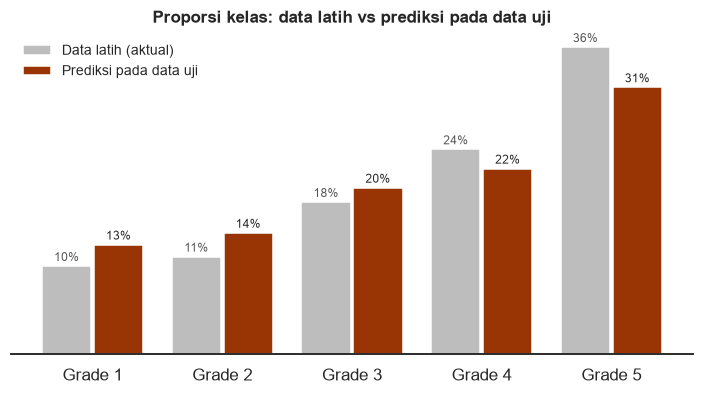

In [5]:
train_share = train[TARGET].value_counts(normalize=True).reindex(GRADE_ORDER)
pred_share = predictions[TARGET].value_counts(normalize=True).reindex(GRADE_ORDER).fillna(0)

display(pd.DataFrame({"latih (aktual)": train_share, "prediksi pada test": pred_share,
                      "selisih (poin persen)": (pred_share - train_share) * 100})
        .style.format({"latih (aktual)": "{:.1%}", "prediksi pada test": "{:.1%}",
                       "selisih (poin persen)": "{:+.1f}"}))

x = np.arange(len(GRADE_ORDER))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(x - 0.2, train_share.values, width=0.38, color="#bdbdbd", label="Data latih (aktual)")
ax.bar(x + 0.2, pred_share.values, width=0.38, color="#993404", label="Prediksi pada data uji")
for xi, a, b in zip(x, train_share.values, pred_share.values):
    ax.text(xi - 0.2, a + 0.006, f"{a:.0%}", ha="center", fontsize=8, color="#555555")
    ax.text(xi + 0.2, b + 0.006, f"{b:.0%}", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(GRADE_ORDER)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.legend(frameon=False, fontsize=9)
ax.set_title("Proporsi kelas: data latih vs prediksi pada data uji")
save_fig("10_prediction_class_distribution")
plt.show()

Data uji berasal dari populasi yang sama dengan data latih (lihat pemeriksaan *distribution shift* pada notebook 01), sehingga proporsi kelas yang sebenarnya pada data uji diperkirakan mirip dengan data latih. Model dilatih dengan bobot kelas seimbang dan dikoreksi bobot keputusan Macro F1, sehingga proporsi prediksi kelas minoritas dapat berbeda dari proporsi aslinya; hal ini disengaja untuk meningkatkan Macro F1 dan bukan kesalahan. Perbedaan yang sangat besar, misalnya satu kelas yang hampir tidak pernah diprediksi, perlu diselidiki.

**Pemeriksaan tambahan:** proporsi prediksi suatu kelas seharusnya mendekati *proporsi aktual × recall ÷ presisi* kelas tersebut pada data hold-out (notebook 02), karena presisi dan recall menentukan seberapa sering kelas itu diprediksi. Kesesuaian yang erat antara angka tersebut dan proporsi prediksi pada data uji menunjukkan bahwa pipeline berperilaku konsisten pada data uji. Bandingkan pula total porsi Grade 4 dan Grade 5: selisih negatif terhadap data latih berarti model cenderung **meremehkan** kerusakan berat secara keseluruhan.

## 5.2 Pola kerusakan antar-distrik
Pada data latih, porsi bangunan berkerusakan berat (Grade 4–5) berbeda sangat jauh antar-distrik (lihat notebook 01). Apabila model telah mempelajari pola wilayah tersebut, porsi prediksi Grade 4–5 per distrik pada data uji harus **sejalan** dengan porsi aktual pada data latih.

Korelasi Pearson porsi Grade 4-5 per distrik (latih vs prediksi): 0.999


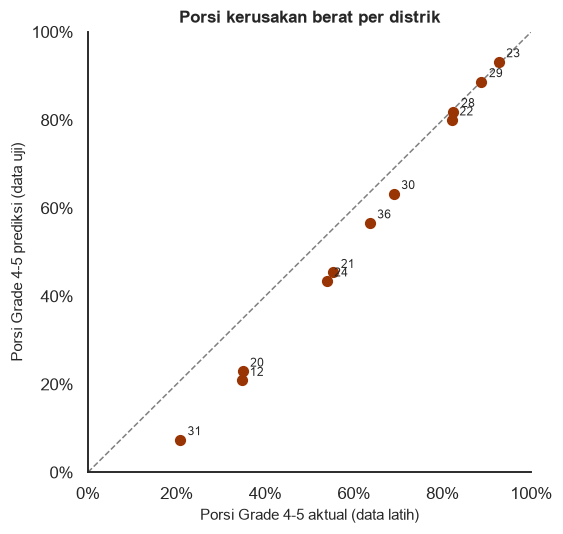

In [6]:
g45_train = train[TARGET].isin(HIGH_DAMAGE).groupby(train["district_id"]).mean()
g45_pred = predictions[TARGET].isin(HIGH_DAMAGE).groupby(test["district_id"].to_numpy()).mean()
district = pd.DataFrame({"latih_aktual": g45_train, "prediksi_test": g45_pred}).dropna()
corr = district["latih_aktual"].corr(district["prediksi_test"])
print(f"Korelasi Pearson porsi Grade 4-5 per distrik (latih vs prediksi): {corr:.3f}")

fig, ax = plt.subplots(figsize=(5.2, 5.2))
lim = (0, 1)
ax.plot(lim, lim, ls="--", color="gray", lw=1)
ax.scatter(district["latih_aktual"], district["prediksi_test"], color="#993404", s=40, zorder=3)
for dist_id, row in district.iterrows():
    ax.annotate(str(dist_id), (row["latih_aktual"], row["prediksi_test"]),
                xytext=(5, 3), textcoords="offset points", fontsize=8)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Porsi Grade 4-5 aktual (data latih)")
ax.set_ylabel("Porsi Grade 4-5 prediksi (data uji)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Porsi kerusakan berat per distrik")
save_fig("11_prediction_district_consistency")
plt.show()

Setiap titik adalah satu distrik, garis putus-putus menunjukkan kesesuaian sempurna. Korelasi Pearson yang tinggi menunjukkan bahwa model mengurutkan distrik dengan benar, tetapi korelasi hanya mengukur keterkaitan linear dan **bukan** kesesuaian nilai: titik dapat berkorelasi sangat tinggi namun tetap berada secara sistematis di bawah atau di atas garis. Perhatikan pola penyimpangannya. Pada prediksi yang memilih kelas dengan probabilitas tertinggi (*argmax*), kelas yang jarang pada suatu wilayah hampir tidak pernah terpilih, sehingga porsi Grade 4–5 prediksi pada distrik berkerusakan rendah dapat jauh lebih kecil daripada aktualnya, sedangkan pada distrik berkerusakan tinggi dapat sama atau sedikit lebih besar (efek "pemenang mengambil semua"). Titik di bawah garis berarti model meremehkan tingkat kerusakan distrik tersebut.

## 5.3 Keyakinan prediksi
Untuk model yang mendukung `predict_proba`, keyakinan prediksi adalah probabilitas kelas yang dipilih. Pada lima kelas, nilai 0,2 setara dengan menebak secara acak.

,jumlah,rata2,median
damage_grade,,,
Grade 1,"29,421",0.683,0.684
Grade 2,"32,611",0.505,0.488
Grade 3,"44,783",0.488,0.465
Grade 4,"49,932",0.589,0.576
Grade 5,"71,882",0.745,0.787


Proporsi prediksi dengan keyakinan < 0,40 : 13.2%


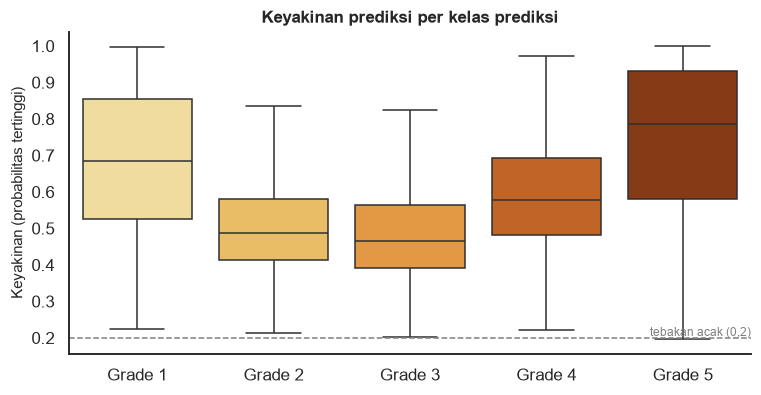

In [7]:
if predictions["confidence"].notna().any():
    conf = (predictions.groupby(TARGET)["confidence"].agg(jumlah="count", rata2="mean", median="median")
            .reindex(GRADE_ORDER))
    display(conf.style.format({"jumlah": "{:,.0f}", "rata2": "{:.3f}", "median": "{:.3f}"}))
    print(f"Proporsi prediksi dengan keyakinan < 0,40 : {(predictions['confidence'] < 0.40).mean():.1%}")

    fig, ax = plt.subplots(figsize=(8, 3.8))
    sns.boxplot(data=predictions, x=TARGET, y="confidence", order=GRADE_ORDER, hue=TARGET,
                hue_order=GRADE_ORDER, palette=GRADE_PALETTE, legend=False, showfliers=False,
                linewidth=1, ax=ax)
    ax.axhline(0.2, color="gray", ls="--", lw=1)
    ax.text(len(GRADE_ORDER) - 0.5, 0.205, "tebakan acak (0,2)", ha="right", fontsize=8, color="gray")
    ax.set_xlabel("")
    ax.set_ylabel("Keyakinan (probabilitas tertinggi)")
    ax.set_title("Keyakinan prediksi per kelas prediksi")
    save_fig("12_prediction_confidence")
    plt.show()
else:
    print("Model ini tidak menyediakan probabilitas (predict_proba); pemeriksaan keyakinan dilewati.")

Keyakinan yang lebih rendah pada kelas menengah (Grade 2 dan 3) sejalan dengan hasil evaluasi hold-out pada notebook 02, yaitu kelas-kelas tersebut paling sulit dibedakan. Prediksi berkeyakinan rendah merupakan kandidat untuk pemeriksaan manual apabila model dipakai untuk prioritas inspeksi lapangan. Pada banyak bangunan, dua kelas yang bersebelahan memiliki probabilitas yang berdekatan (misalnya Grade 4 dan Grade 5), sehingga pilihan kelas akhir sensitif terhadap selisih kecil. Keyakinan model tidak identik dengan ketepatan: model dapat yakin namun keliru.

# 6. Mengunggah ke Kaggle
Berkas yang diunggah adalah `submissions/submission.csv`. Aturan kompetisi membatasi **maksimal 5 submission per hari**, dan pada akhir kompetisi **maksimal 2 submission final** harus dipilih untuk dinilai. 

**Cara 1 — melalui web:** buka halaman kompetisi, klik **Submit Prediction**, pilih **Upload Submission File**, lalu pilih `submission.csv`.

**Cara 2 — melalui command line** (membutuhkan `kaggle.json` dan aturan kompetisi sudah diterima di web):
```bash
kaggle competitions submit -c structural-damage-classification -f submissions/submission.csv -m "HistGradientBoosting + fitur tetangga ID, hold-out Macro F1 0.576"
```

# 7. Ringkasan dan kesimpulan

## Interpretasi
Skor *public leaderboard* pada Kaggle dihitung dari sebagian data uji, sedangkan *private leaderboard* dari sisanya dan baru terlihat setelah kompetisi berakhir. Sebagai acuan, estimasi Macro F1 pada data *hold-out* di notebook 02 adalah sekitar 0,58 (sebelumnya ±0,53 dengan Random Forest tanpa fitur tetangga). Model akhir dilatih pada seluruh data latih sehingga tetangga berlabel lebih rapat dan skornya dapat sedikit berbeda dari acuan. Skor leaderboard yang jauh di bawah acuan tersebut menandakan adanya masalah proses (misalnya model atau berkas yang keliru), sedangkan selisih kecil merupakan variasi yang wajar karena perbedaan sampel.

## Limitasi
- **Pemeriksaan pada bagian 5 tidak menggunakan label data uji**, sehingga hanya dapat mendeteksi ketidakwajaran, bukan mengukur ketepatan.
- **Berkas model terikat pada versi pustaka.** Jalankan notebook ini dengan versi scikit-learn yang sama dengan saat pelatihan (periksa peringatan pada bagian 2).
- **Fitur tetangga memanfaatkan struktur `building_id`**, yaitu label bangunan berlabel dengan ID berdekatan. Fitur ini sah secara aturan kompetisi dan tidak membocorkan label data uji, tetapi ia menangkap struktur urutan survei, bukan sifat fisik bangunan, sehingga tidak akan tersedia pada gempa baru yang belum memiliki label tetangga.
- **Bobot keputusan disetel pada hold-out 20% dan diterapkan pada model yang dilatih pada 100% data** (kerapatan tetangga berlabel berbeda), sehingga bobot optimalnya dapat sedikit bergeser.
- **Hanya satu model yang dipakai.** Peningkatan lebih lanjut dapat dicoba melalui ensambel model, pemanfaatan struktur ordinal target, atau fitur residual tetangga (yang pada uji awal hanya menambah ±0,004 Macro F1).

## Langkah berikutnya
Menyusun `README.md` yang memuat cara menjalankan repositori (unduh data, `setup.bat`, urutan notebook), ringkasan metode, dan laporan interpretasi hasil.